# 3. HMM multivarié, choix du nombre d'états et probabilités filtrées

On passe à 3 variables : `ret`, `vol_21` et `log(VIX)`. Elles ont des échelles très différentes, donc on les standardise.

⚠️ Ici, le `StandardScaler` et le HMM sont encore ajustés sur toute la période. On corrige ça au notebook 4.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Remonte jusqu'au dossier qui contient src/, quel que soit l'endroit d'où on lance
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
DATA = root / "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler

from src.data import download_prices
from src.features import hmm_features
from src.models import (STATE_NAMES, expected_durations, filtered_probs,
                        fit_best_hmm, order_states, state_order)

df = pd.read_parquet(DATA / "features.parquet")
feats = hmm_features(df)
X_multi = StandardScaler().fit_transform(feats)
feats.describe().round(3)

,ret,vol_21,log_vix
count,6697.000,6697.000,6697.000
mean,0.000,0.162,2.915
std,0.012,0.105,0.353
min,-0.128,0.035,2.213
25%,-0.005,0.099,2.643
50%,0.001,0.135,2.872
75%,0.006,0.194,3.136
max,0.110,0.976,4.415


## 3.1 Choisir le nombre d'états avec le BIC

Pour chaque nombre d'états, on entraîne 5 modèles avec des initialisations différentes et on garde le meilleur (l'EM peut tomber dans un optimum local). Le BIC pénalise la log-vraisemblance par le nombre de paramètres : **plus il est bas, mieux c'est**.

Cette cellule prend une à deux minutes.

2 états : BIC = 34,902


3 états : BIC = 29,545


4 états : BIC = 25,269


5 états : BIC = 22,684


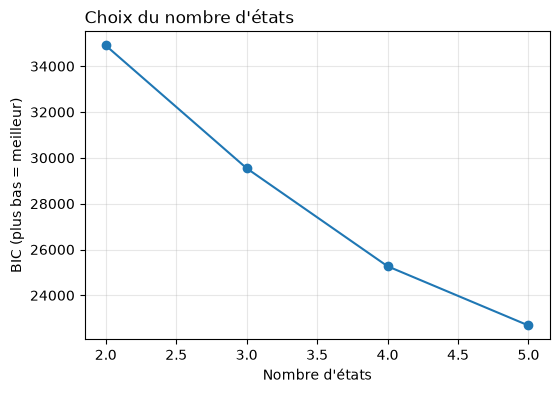

In [3]:
bic = {}
for n in range(2, 6):
    best = fit_best_hmm(X_multi, n, n_seeds=5)
    bic[n] = best.bic(X_multi)
    print(f"{n} états : BIC = {bic[n]:,.0f}")

plt.figure(figsize=(6, 4))
plt.plot(list(bic.keys()), list(bic.values()), marker="o")
plt.xlabel("Nombre d'états")
plt.ylabel("BIC (plus bas = meilleur)")
plt.title("Choix du nombre d'états", loc="left")
plt.grid(alpha=0.3)
plt.show()

Le BIC baisse encore à 5 états, mais le choix ne se fait pas sur le BIC seul : il faut des régimes **interprétables et persistants**, qu'on peut utiliser dans une stratégie. On garde **4 états**, à vérifier ci-dessous :

- volatilités bien ordonnées ;
- toutes les durées moyennes supérieures à quelques semaines ;
- une structure de transition lisible.

## 3.2 Le modèle à 4 états

In [4]:
model = fit_best_hmm(X_multi, 4, n_seeds=5)
order = state_order(model, feature=1)            # ordre par vol_21 croissante
states, T = order_states(model, model.predict(X_multi), feature=1)

summary = pd.DataFrame({
    "Rendement annualisé": [df["ret"][states == i].mean() * 252 for i in range(4)],
    "Volatilité annualisée": [df["ret"][states == i].std() * np.sqrt(252) for i in range(4)],
    "VIX moyen": [df["vix"][states == i].mean() for i in range(4)],
    "Part des jours": [(states == i).mean() for i in range(4)],
    "Durée moyenne (jours)": expected_durations(T),
}, index=STATE_NAMES)

summary.style.format({
    "Rendement annualisé": "{:+.1%}", "Volatilité annualisée": "{:.1%}",
    "VIX moyen": "{:.1f}", "Part des jours": "{:.0%}", "Durée moyenne (jours)": "{:.0f}",
})

,Rendement annualisé,Volatilité annualisée,VIX moyen,Part des jours,Durée moyenne (jours)
calme,+17.7%,8.0%,12.5,24%,38
tendu,+15.2%,11.9%,16.5,33%,27
nervosite,-3.7%,18.7%,22.5,30%,35
crise,-16.9%,39.2%,35.3,13%,40


In [5]:
pd.DataFrame(T, index=STATE_NAMES, columns=STATE_NAMES).style.format("{:.3f}").background_gradient(cmap="Blues")

,calme,tendu,nervosite,crise
calme,0.974,0.026,0.000,0.000
tendu,0.020,0.963,0.016,0.001
nervosite,0.000,0.019,0.971,0.010
crise,0.000,0.000,0.025,0.975


**La structure en échelle.** La matrice de transition est presque tridiagonale : le marché passe calme ↔ tendu ↔ nervosité ↔ crise, presque sans sauter d'étape. Le seul raccourci notable (tendu → crise) est très rare : ce sont les chocs brutaux comme mars 2020. La sortie de crise passe par la nervosité, jamais directement par le calme.

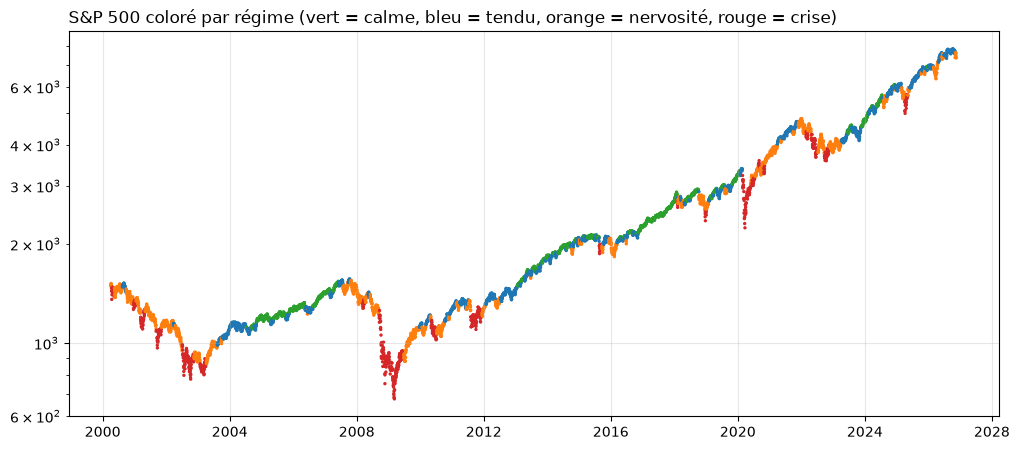

In [6]:
REGIME_COLORS = ["tab:green", "tab:blue", "tab:orange", "tab:red"]
prices = download_prices("^GSPC").loc[df.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(df.index, prices, c=states, cmap=ListedColormap(REGIME_COLORS), s=2, vmin=0, vmax=3)
ax.set_yscale("log")
ax.set_title("S&P 500 coloré par régime (vert = calme, bleu = tendu, orange = nervosité, rouge = crise)", loc="left")
ax.grid(alpha=0.3)
plt.show()

## 3.3 Probabilités filtrées : sortir du look-ahead du décodage

`predict()` et `predict_proba()` utilisent toute la série. Pour décider en temps réel, il faut P(état_t | x_1, …, x_t) : c'est l'**algorithme forward** (`filtered_probs` dans `src/models.py`). Chaque jour :

1. **prédire** : `alpha[t-1] @ T` donne les probabilités du jour avant de voir ses données ;
2. **corriger** : on multiplie par la vraisemblance de l'observation du jour, puis on normalise.

In [7]:
filt = filtered_probs(model, X_multi)[:, order]
smooth = model.predict_proba(X_multi)[:, order]

print("Lignes qui somment à 1 :", np.allclose(filt.sum(axis=1), 1))
print("Dernier jour identique filtré / lissé :", np.allclose(filt[-1], smooth[-1], atol=1e-6))
print(f"Accord filtré / predict : {(filt.argmax(axis=1) == states).mean():.1%}")

Lignes qui somment à 1 : True
Dernier jour identique filtré / lissé : True
Accord filtré / predict : 94.0%


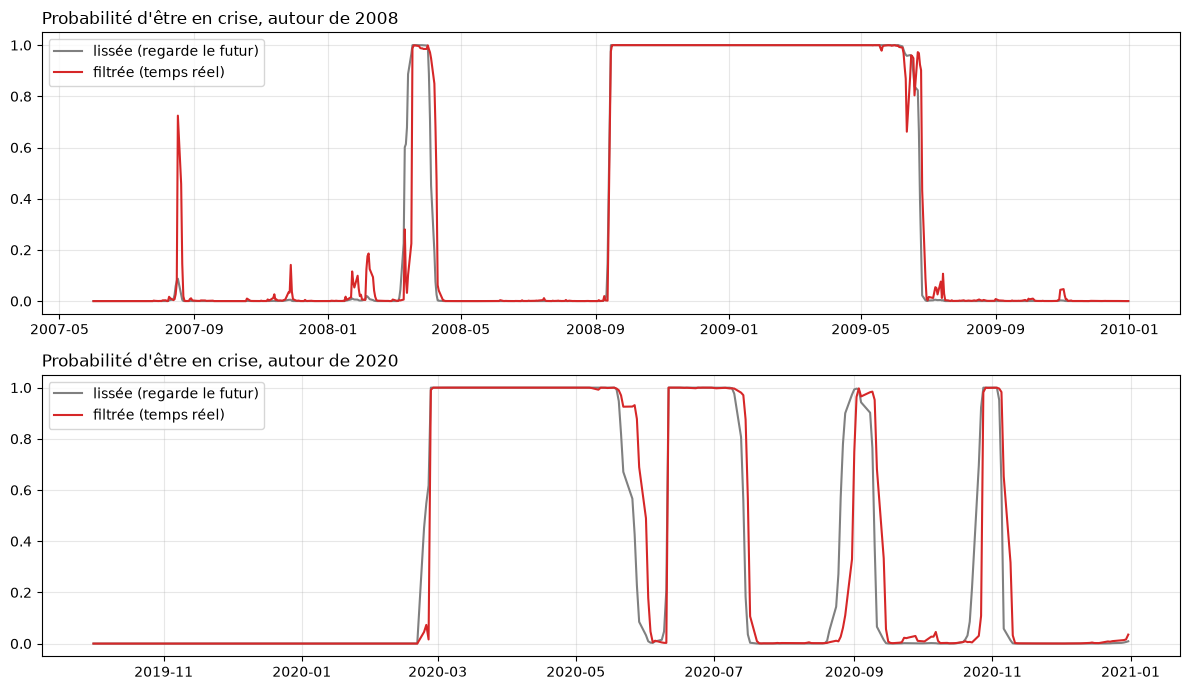

In [8]:
windows = {"2008": ("2007-06-01", "2009-12-31"), "2020": ("2019-10-01", "2020-12-31")}

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (label, (start, end)) in zip(axes, windows.items()):
    zoom = (df.index >= start) & (df.index <= end)
    ax.plot(df.index[zoom], smooth[zoom, 3], color="gray", label="lissée (regarde le futur)")
    ax.plot(df.index[zoom], filt[zoom, 3], color="tab:red", label="filtrée (temps réel)")
    ax.set_title(f"Probabilité d'être en crise, autour de {label}", loc="left")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Retard du filtre : premier jour où P(crise) dépasse 50 % dans chaque fenêtre
for label, (start, end) in windows.items():
    zoom = (df.index >= start) & (df.index <= end)
    dates = df.index[zoom]
    above_smooth = dates[smooth[zoom, 3] > 0.5]
    above_filt = dates[filt[zoom, 3] > 0.5]
    if len(above_smooth) == 0 or len(above_filt) == 0:
        print(f"{label} : P(crise) ne dépasse jamais 50 % dans la fenêtre")
        continue
    first_smooth, first_filt = above_smooth[0], above_filt[0]
    lag = np.busday_count(first_smooth.date(), first_filt.date())
    print(f"{label} : lissée {first_smooth.date()}, filtrée {first_filt.date()} → retard de {lag} jours ouvrés")

2008 : lissée 2008-03-11, filtrée 2007-08-17 → retard de -147 jours ouvrés
2020 : lissée 2020-02-25, filtrée 2020-02-27 → retard de 2 jours ouvrés


Le filtre suit la probabilité lissée avec quelques jours de retard au début des crises : c'est le prix d'une détection honnête. Il reste un biais : les paramètres du modèle et du scaler ont été appris sur toute la période. C'est l'objet du walk-forward.